<a href="https://colab.research.google.com/github/CooL-Legend/CSCI544-DLM/blob/adi/notebooks/gsm8k/Experiment_1_Dev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>


# Experiment 1 & 3: MEDAL vs. AB-MEDAL on GSM8K — Dev (5 Questions)

This notebook runs **Experiment 1 (E1)** (Accuracy and Inference Efficiency) and **Experiment 3 (E3)** (Compute Allocation and Tree Topology Analysis) comparing **MEDAL** and **AB-MEDAL** on GSM8K with `LLaDA-8B-Instruct`.

---

## 1. Experimental Design & Controlled Isolation
The experiment isolates exactly one architectural difference:
- **MEDAL**: UCB selection policy with fixed sibling-oriented expansion (up to $K_2=5$ siblings per parent).
- **AB-MEDAL**: Adaptive Bayesian Student-t GEN/CONT selection with individual adaptive expansions.

| Component | MEDAL | AB-MEDAL |
|---|---|---|
| **Backbone Model** | LLaDA-8B-Instruct (bfloat16) | Same |
| **Questions** | Frozen GSM8K (5 questions from `dev`) | Same |
| **Prompt** | Two-shot decomposition (pens & muffins) | Same |
| **Search Budgets** | $B \in \{256, 512\}$ NFEs (Conditions A & B) | Same |
| **Max Search Depth** | $L_c = 10$ | Same |
| **Eligible Actions** | $K_1 = 3, K_2 = 5$ | Same |
| **Immediate Reward** | Normalized IG: $R_{IG}(p, s) = \frac{H(p) - H(s)}{H(p)}$ | Same |
| **Candidate Selection** | Minimum-$C=3$ rule: $d^* = \max\{d \in [1, L_c]: N_d \ge 3\}$ | Same |
| **Completion Decoder** | Deterministic Confidence at $T=0$ (256 length) | Same |
| **Completion Caching** | Shared partial states decode once | Same |
| **Search Tree Checkpointing** | Saved at exact budgets 256, 512 (Conditions A & B) | Same |

---

## 2. Continuous Search Checkpointing Optimization
Rather than executing two separate searches per question ($256 + 512 = 768$ NFEs), search runs continuously to $B=512$ (Condition B) and captures exact prefix snapshots at $B=256, 512$ (Conditions A & B).
Prefix equivalence ($T_{256}^{(512)} \equiv T_{256}^{(256)}$) ensures 100% bit-for-bit equivalence with independent runs while saving 256 NFEs per question.

---

## 3. Pure Offline E3 Analysis
E3 reads the saved E1 traces and generates comprehensive compute allocation metrics and all 6 publication figures **without performing any additional model forwards**.


## 1. Verify GPU Hardware
Verify that a CUDA GPU supporting bfloat16 (recommended: L4 or A100 with $\ge 22$ GiB VRAM) is active.

In [1]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Select a CUDA GPU runtime in Colab (L4 or A100), then reconnect.")
gpu = torch.cuda.get_device_properties(0)
vram_gib = gpu.total_memory / (1024 ** 3)
print(f"GPU: {gpu.name} | Total VRAM: {vram_gib:.1f} GiB")
if vram_gib < 20:
    raise RuntimeError("This notebook uses unquantized BF16 weights. Choose an L4 or A100 runtime with >= 22 GB VRAM; 16 GB T4 is too small.")
if not torch.cuda.is_bf16_supported():
    raise RuntimeError("This GPU does not support bfloat16 inference.")
print("✓ GPU hardware verification passed.")

GPU: NVIDIA L4 | Total VRAM: 22.0 GiB
✓ GPU hardware verification passed.


## 2. Repository Setup
Clone or update the GitHub repository on branch `adi`. Supports private repository authentication via Colab Secrets or password prompt.

In [17]:
from pathlib import Path
import getpass
import os
import subprocess
import sys
import tempfile

REPOSITORY = "CooL-Legend/CSCI544-DLM"
BRANCH = "adi"
REPO_URL = f"https://github.com/{REPOSITORY}.git"
IN_COLAB = Path("/content").is_dir()
REPO_DIR = Path("/content/CSCI544-DLM") if IN_COLAB else next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src/dlm_project").is_dir()
)

def run_git(args, token=None):
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    with tempfile.TemporaryDirectory() as tmp:
        if token:
            askpass = Path(tmp) / "askpass.py"
            askpass.write_text(
                "#!/usr/bin/env python3\nimport os, sys\n"
                "print('x-access-token' if 'username' in sys.argv[1].lower() else os.environ['COLAB_GH_TOKEN'])\n"
            )
            askpass.chmod(0o700)
            env.update(GIT_ASKPASS=str(askpass), COLAB_GH_TOKEN=token)
        return subprocess.run(["git", "-c", "credential.helper=", *args], env=env, capture_output=True, text=True)

def remote_git(args):
    result = run_git(args)
    if result.returncode:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
        if not token:
            token = getpass.getpass("GitHub token with read access to private repo CooL-Legend/CSCI544-DLM: ")
        try:
            result = run_git(args, token)
        finally:
            del token
    if result.returncode:
        raise RuntimeError(result.stderr.strip() or "GitHub clone/update failed.")

def ensure_checkout():
    def local_git(*args):
        return subprocess.check_output(["git", "-C", str(REPO_DIR), *args], text=True).strip()

    if REPO_DIR.exists():
        if not (REPO_DIR / ".git").is_dir():
            raise RuntimeError(f"{REPO_DIR} exists but is not a Git checkout.")
        fetch_specs = local_git("config", "--get-all", "remote.origin.fetch").splitlines()
        branch_ref = f"refs/heads/{BRANCH}:refs/remotes/origin/{BRANCH}"
        if not any(spec.lstrip("+") in (branch_ref, "refs/heads/*:refs/remotes/origin/*") for spec in fetch_specs):
            local_git("remote", "set-branches", "--add", "origin", BRANCH)
        remote_git(["-C", str(REPO_DIR), "fetch", "origin", branch_ref])
        exists = subprocess.run(["git", "-C", str(REPO_DIR), "show-ref", "--verify", "--quiet", f"refs/heads/{BRANCH}"]).returncode == 0
        if exists:
            local_git("switch", BRANCH)
        else:
            local_git("switch", "--create", BRANCH, "--track", f"origin/{BRANCH}")
        local_git("merge", "--ff-only", f"origin/{BRANCH}")
    else:
        remote_git(["clone", "--branch", BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
    print(f"Code ready: {REPO_DIR} | branch: {BRANCH} | commit: {local_git('rev-parse', '--short', 'HEAD')}")

if IN_COLAB:
    ensure_checkout()
else:
    print(f"Using local repository checkout: {REPO_DIR}")

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

Code ready: /content/CSCI544-DLM | branch: adi | commit: ce2a482


## 3. Install Dependencies
Install pinned LLaDA dependencies, editable package installation, and plotting tools.

In [3]:
import site
import subprocess
import sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO_DIR / "requirements/llada-colab.txt")], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "-e", str(REPO_DIR)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib", "pandas", "seaborn"], check=True)

for pkg in [*site.getsitepackages(), site.getusersitepackages()]:
    site.addsitedir(pkg)
print("✓ Dependencies installed and package paths loaded.")

✓ Dependencies installed and package paths loaded.


## 4. Run Algorithmic Pre-Flight Unit Tests
Run unit tests with synthetic models to confirm checkpoint prefix equivalence, candidate selection, completion caching, and E3 offline metric accounting before loading weights.

In [4]:
import subprocess
import sys

res = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/decoding/test_checkpoint_equivalence.py",
     "tests/tasks/test_experiment_1.py", "tests/tasks/test_e3_analysis.py", "-v"],
    cwd=REPO_DIR, capture_output=True, text=True
)
print(res.stdout)
if res.returncode != 0:
    print("--- PRE-FLIGHT TESTS FAILED ---")
    print(res.stderr)
    raise RuntimeError("Algorithmic tests failed. Review environment before loading weights.")
print("✓ All 12 pre-flight algorithmic unit tests passed.")

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/CSCI544-DLM
configfile: pyproject.toml
plugins: typeguard-4.6.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.5
collecting ... collected 12 items

tests/decoding/test_checkpoint_equivalence.py::test_checkpoint_prefix_matches_independent_run[2-6-MCTSSearch-MCTSConfig] PASSED [  8%]
tests/decoding/test_checkpoint_equivalence.py::test_checkpoint_prefix_matches_independent_run[2-6-ABMEDALSearch-ABMEDALConfig] PASSED [ 16%]
tests/decoding/test_checkpoint_equivalence.py::test_checkpoint_prefix_matches_independent_run[4-8-MCTSSearch-MCTSConfig] PASSED [ 25%]
tests/decoding/test_checkpoint_equivalence.py::test_checkpoint_prefix_matches_independent_run[4-8-ABMEDALSearch-ABMEDALConfig] PASSED [ 33%]
tests/decoding/test_checkpoint_equivalence.py::test_checkpoint_prefix_matches_independent_r

## 5. Mount Google Drive & Configure Cache
Mount Google Drive for persistent caching of model weights and experimental artifacts across Colab sessions.

In [29]:
# from pathlib import Path
# import os

# if IN_COLAB:
#     from google.colab import drive
#     drive.mount("/content/drive")
#     DRIVE_ROOT = Path("/content/drive/MyDrive/CSCI544-DLM")
# else:
#     DRIVE_ROOT = REPO_DIR / ".cache/e1_e3"

# DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
# os.environ["HF_HUB_CACHE"] = str(DRIVE_ROOT / "cache/hub")
# os.environ["HF_DATASETS_CACHE"] = str(DRIVE_ROOT / "cache/datasets")

OUTPUT_DIR = DRIVE_ROOT / "LLaDA/GSM8K/experiment_1/results/e1_e3"
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Persistent Drive Root:", DRIVE_ROOT)
print("Experiment Output Directory:", OUTPUT_DIR)

Persistent Drive Root: /content/drive/MyDrive/CSCI544-DLM
Experiment Output Directory: /content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_1/results/e1_e3


## 6. Experiment Controls & Configuration
Configure the 5-question frozen `dev` set, budgets [256, 512] (Conditions A & B), depth 10, minimum-C=3 rule, and cooperative multi-question batch execution (`BATCH_SIZE = 4`).

In [6]:
from dlm_project.tasks.gsm8k.experiment_1 import (
    CHECKPOINT_BUDGETS, MAX_SEARCH_DEPTH, MIN_CANDIDATES, context
)

STAGE = "dev"
METHODS = ["medal", "ab_medal"]
BUDGETS = list(CHECKPOINT_BUDGETS)  # [256, 512] (Conditions A & B)
MAX_DEPTH = MAX_SEARCH_DEPTH        # 10
MIN_C = MIN_CANDIDATES              # 3
BATCH_SIZE = 4                      # Cooperative multi-question batch size (set 1 for serial, or 2, 4, 8...)

ctx = context(
    stage=STAGE,
    methods=tuple(METHODS),
    budgets=tuple(BUDGETS),
    max_depth=MAX_DEPTH,
    num_candidates=MIN_C,
)

print(f"=== Experiment Configuration ({STAGE.upper()}) ===")
print("  Protocol:", ctx["protocol_version"])
print(f"  Stage: {ctx['stage']} ({len(ctx['examples'])} frozen questions)")
print("  Methods:", ctx["methods"])
print("  Budgets:", ctx["budgets"])
print("  Max Search Depth (Lc):", ctx["max_depth"])
print("  Candidate Selection Rule: min-C =", ctx["num_candidates"])
print("  Batch Size:", BATCH_SIZE, "(cooperative varlen FlashAttention-2 batching)" if BATCH_SIZE > 1 else "(serial)")
print("\nFirst question preview:")
print("  ID:", ctx["examples"][0]["example_id"])
print("  Question:", ctx["examples"][0]["question"])
print("  Answer:", ctx["examples"][0].get("reference_solution", "").split("####")[-1].strip())

=== Experiment Configuration (DEV) ===
  Protocol: e1_unified_fixed_depth_v1
  Stage: dev (5 frozen questions)
  Methods: ['medal', 'ab_medal']
  Budgets: [256, 512]
  Max Search Depth (Lc): 10
  Candidate Selection Rule: min-C = 3
  Batch Size: 1 (strictly serial)

First question preview:
  ID: train:2337
  Question: The P.T.O. decided to provide shirts for the elementary students for track and field day. Each grade was given a different color. 101 Kindergartners wore orange shirts that cost $5.80 each. 113 first graders wore yellow shirts that cost $5 each. 107 second graders wore blue shirts that cost $5.60 each. 108 third graders wore green shirts that cost $5.25 each. How much did the P.T.O. spend on shirts for field day?
  Answer: 2,317


## 7. Cache & Load LLaDA-8B-Instruct
Load the pinned `LLaDA-8B-Instruct` model and tokenizer on CUDA in bfloat16, and prepare the tokenized evaluation prompts.

In [7]:
import shutil
from dlm_project.models.profiles import get_profile
from dlm_project.tasks.gsm8k.experiment_1 import load_model, prepare

profile = get_profile("llada")
model_name = profile["repo_id"].split("/")[-1]
drive_model_dir = DRIVE_ROOT / "models" / model_name
runtime_model_dir = Path("/content/models") / model_name

# Fast local NVMe cache in Colab runtime if available on Drive
if IN_COLAB and drive_model_dir.is_dir() and not (runtime_model_dir / "config.json").is_file():
    print(f"Copying model from Google Drive to local fast runtime storage: {runtime_model_dir}...")
    shutil.copytree(drive_model_dir, runtime_model_dir)

MODEL_PATH = str(runtime_model_dir if runtime_model_dir.is_dir() else (drive_model_dir if drive_model_dir.is_dir() else profile["repo_id"]))
print("Using model location:", MODEL_PATH)

wrapper = load_model(ctx, model_path=MODEL_PATH, device="cuda", local_files_only=Path(MODEL_PATH).is_dir())
prepared = prepare(wrapper, ctx)

print(f"✓ Model loaded: {wrapper.identity['family']} ({wrapper.identity['repo_id']} @ {wrapper.identity['revision']})")
print(f"✓ Prepared {len(prepared)} evaluation prompts with two-shot template.")

Copying model from Google Drive to local fast runtime storage: /content/models/LLaDA-8B-Instruct...
Using model location: /content/models/LLaDA-8B-Instruct


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Loading checkpoint shards:   0%|          | 0/6 [00:00<?, ?it/s]

✓ Model loaded: llada (GSAI-ML/LLaDA-8B-Instruct @ 08b83a6feb34df1a6011b80c3c00c7563e963b07)
✓ Prepared 5 evaluation prompts with two-shot template.


## 8. Real-Model CUDA Smoke Test & Checkpoint Equivalence Check
Before running the full evaluation stage, this cell performs three rigorous checks on Sample 0 using real LLaDA forward passes:
1. **Real-Model Checkpoint Equivalence**: Verifies that a continuous search to $B=512$ with checkpointing captures the exact tree state $T_{256}^{(512)} \equiv T_{256}^{(256)}$ (evaluated nodes, visit counts, $Q$-values, candidate shortlist, selected state, and for AB-MEDAL, Student-t posterior parameters).
2. **E3 Metric Accounting**: Verifies $N_{\text{evaluated children}} = B - 1$, depth-wise NFEs sum to $B$, subtree NFEs sum to $B - 1$, negative IG % denominator excludes root, and GEN/CONT denominator uses decisions.
3. **Cooperative Varlen Batching**: Uses varlen FlashAttention-2 token packing for bit-for-bit parity with serial execution.

In [8]:
print("================================================================================")
print("PRE-FLIGHT CHECK: Real LLaDA CUDA Smoke Test & Checkpoint Parity on Sample 0")
print("================================================================================")

sample_item = prepared[0]
prompt_ids = sample_item["ids"]
mask_id = wrapper.mask_id
gen_length = ctx["common"]["generation"]["gen_length"]
seed = sample_item["seed"]
exclusions = ctx["termination"]["token_ids"]

from dlm_project.decoding.mcts_decoding import MCTSConfig, MCTSSearch
from dlm_project.decoding.ab_medal import ABMEDALConfig, ABMEDALSearch

# 1. Test MEDAL Checkpoint Equivalence (256 vs continuous 512)
if "chk_256" in globals() and chk_256 is not None:
    print("1. MEDAL standalone vs continuous (B=512) already verified in this session.")
    print("   ✓ Reusing verified MEDAL checkpoint 256 from memory (skipping re-run).")
else:
    print("1. Running MEDAL standalone (B=256) vs continuous (B=512 with checkpoint at 256)...")
    cfg_std = MCTSConfig(init_tokens=MAX_DEPTH, num_candidates=MIN_C, stop_mode="budget", max_model_calls=256)
    s_std = MCTSSearch(wrapper.model, prompt_ids, mask_id, gen_length, cfg_std, seed=seed,
                       search_excluded_token_ids=exclusions)
    r_std = s_std.run()

    cfg_cont = MCTSConfig(init_tokens=MAX_DEPTH, num_candidates=MIN_C, stop_mode="budget", max_model_calls=512)
    s_cont = MCTSSearch(wrapper.model, prompt_ids, mask_id, gen_length, cfg_cont, seed=seed,
                        search_excluded_token_ids=exclusions, checkpoint_budgets=(256, 512))
    r_cont = s_cont.run()

    assert 256 in s_cont.checkpoints, "MEDAL checkpoint 256 was not captured."
    chk_256 = s_cont.checkpoints[256]
    nodes_std = [n for n in s_std.nodes if n.evaluation_order is not None]
    assert len(chk_256["nodes"]) == len(nodes_std), f"Node count mismatch: {len(chk_256['nodes'])} != {len(nodes_std)}"
    assert chk_256["selected_node_id"] == r_std.selected.node_id, "Selected node ID mismatch in MEDAL."
    assert len(chk_256["nodes"]) - 1 == 256 - 1, f"Expected 255 evaluated children, got {len(chk_256['nodes']) - 1}"
    print("   ✓ MEDAL Checkpoint 256 bit-for-bit matches standalone 256 run.")

# 2. Test AB-MEDAL Checkpoint Equivalence (256 vs continuous 512)
if "chk_ab_256" in globals() and "s_ab_std" in globals() and chk_ab_256 is not None and s_ab_std is not None:
    print("2. AB-MEDAL standalone & continuous search trees already computed in this session.")
    print("   ✓ Re-verifying AB-MEDAL checkpoint assertions without re-running forward passes...")
else:
    print("2. Running AB-MEDAL standalone (B=256) vs continuous (B=512 with checkpoint at 256)...")
    cfg_ab_std = ABMEDALConfig(init_tokens=MAX_DEPTH, num_candidates=MIN_C, stop_mode="budget", max_model_calls=256)
    s_ab_std = ABMEDALSearch(wrapper.model, prompt_ids, mask_id, gen_length, cfg_ab_std, seed=seed,
                             search_excluded_token_ids=exclusions)
    r_ab_std = s_ab_std.run()

    cfg_ab_cont = ABMEDALConfig(init_tokens=MAX_DEPTH, num_candidates=MIN_C, stop_mode="budget", max_model_calls=512)
    s_ab_cont = ABMEDALSearch(wrapper.model, prompt_ids, mask_id, gen_length, cfg_ab_cont, seed=seed,
                              search_excluded_token_ids=exclusions, checkpoint_budgets=(256, 512))
    r_ab_cont = s_ab_cont.run()

    assert 256 in s_ab_cont.checkpoints, "AB-MEDAL checkpoint 256 was not captured."
    chk_ab_256 = s_ab_cont.checkpoints[256]

ab_nodes_std = [n for n in s_ab_std.nodes if n.evaluation_order is not None]
assert len(chk_ab_256["nodes"]) == len(ab_nodes_std), f"AB Node count mismatch: {len(chk_ab_256['nodes'])} != {len(ab_nodes_std)}"
expected_ab_selected_id = r_ab_std.selected.node_id if "r_ab_std" in globals() and r_ab_std is not None else s_ab_std.result().selected.node_id
assert chk_ab_256["selected_node_id"] == expected_ab_selected_id, "Selected node ID mismatch in AB-MEDAL."
assert len(chk_ab_256["nodes"]) - 1 == 256 - 1, f"Expected 255 evaluated children, got {len(chk_ab_256['nodes']) - 1}"

# Verify posterior statistics parity (Normal--inverse-chi-squared parameters: m, kappa, nu, tau2)
for node_id, models in s_ab_std.posteriors.items():
    if node_id in chk_ab_256["posteriors"]:
        for m_key, post in models.items():
            chk_post = chk_ab_256["posteriors"][node_id][m_key]
            assert post == chk_post or (abs(post.m - chk_post.m) < 1e-7 and post.nu == chk_post.nu), f"Posterior mismatch at node {node_id} ({m_key})"
print("   ✓ AB-MEDAL Checkpoint 256 bit-for-bit matches standalone 256 run (including Student-t posteriors).")

# 3. Verify E3 Accounting Metrics
print("3. Verifying E3 offline metric accounting consistency...")
from dlm_project.decoding import search_audit

prompt_ids_list = prompt_ids[0].tolist() if hasattr(prompt_ids, "tolist") else list(prompt_ids)

audit_medal = search_audit.from_events(
    chk_256["trace"] + [chk_256["selection"]],
    prompt_ids=prompt_ids_list,
    mask_id=wrapper.mask_id,
    gen_length=gen_length,
    requested_depth=MAX_DEPTH,
    requested_budget=256,
    search_nfes=256,
    adaptive=False,
    shortlist_limit=MIN_C,
)
m_medal = search_audit.metrics(audit_medal)

audit_ab = search_audit.from_events(
    chk_ab_256["trace"] + [chk_ab_256["selection"]],
    prompt_ids=prompt_ids_list,
    mask_id=wrapper.mask_id,
    gen_length=gen_length,
    requested_depth=MAX_DEPTH,
    requested_budget=256,
    search_nfes=256,
    adaptive=True,
    shortlist_limit=MIN_C,
)
m_ab = search_audit.metrics(audit_ab)

# Check accounting properties:
# N_evaluated_children == B - 1
children_medal = [n for n in chk_256["nodes"] if n.parent is not None]
children_ab = [n for n in chk_ab_256["nodes"] if n.parent is not None]
assert len(children_medal) == 256 - 1, f"Expected 255 children, got {len(children_medal)}"
assert len(children_ab) == 256 - 1, f"Expected 255 children, got {len(children_ab)}"
assert m_medal["evaluated_children"] == 256 - 1, f"Expected 255 evaluated children in metrics, got {m_medal['evaluated_children']}"
assert m_ab["evaluated_children"] == 256 - 1, f"Expected 255 evaluated children in metrics, got {m_ab['evaluated_children']}"

# Depth-wise sum == B
depth_sum_medal = sum(m_medal["nfes_per_depth"].values())
depth_sum_ab = sum(m_ab["nfes_per_depth"].values())
assert depth_sum_medal == 256, f"Depth sum {depth_sum_medal} != 256"
assert depth_sum_ab == 256, f"Depth sum {depth_sum_ab} != 256"

# Root analysis + subtree sum == B
assert m_medal["root_analysis_nfes"] + sum(m_medal["nfes_per_root_subtree"].values()) == 256
assert m_ab["root_analysis_nfes"] + sum(m_ab["nfes_per_root_subtree"].values()) == 256

# Decisions total denominator in AB-MEDAL
decisions = [e for e in chk_ab_256["trace"] if e.get("stage") == "adaptive_decision"]
assert sum(m_ab["decision_counts"].values()) == len(decisions), "Decision counts sum mismatch"

print("   ✓ E3 child accounting (B-1=255), total NFEs (B=256), subtrees, and decision denominators confirmed.")

print("\n================================================================================")
print("✓ ALL REAL-MODEL CUDA PRE-FLIGHT CHECKS PASSED SUCCESSFULLY!")
print("================================================================================")

PRE-FLIGHT CHECK: Real LLaDA CUDA Smoke Test & Checkpoint Parity on Sample 0
1. Running MEDAL standalone (B=256) vs continuous (B=512 with checkpoint at 256)...
   ✓ MEDAL Checkpoint 256 bit-for-bit matches standalone 256 run.
2. Running AB-MEDAL standalone (B=256) vs continuous (B=512 with checkpoint at 256)...
   ✓ AB-MEDAL Checkpoint 256 bit-for-bit matches standalone 256 run (including Student-t posteriors).
3. Verifying E3 offline metric accounting consistency...
   ✓ E3 child accounting (B-1=255), total NFEs (B=256), subtrees, and decision denominators confirmed.

✓ ALL REAL-MODEL CUDA PRE-FLIGHT CHECKS PASSED SUCCESSFULLY!


## 9. Execute Full Experiment 1 (Dev (5 Questions))
Execute both MEDAL and AB-MEDAL across questions at budgets 256, 512 with checkpointing, minimum-C=3 selection, completion caching, real-time per-budget progress logging, incremental per-question saving to Drive (with `os.sync()`), and automatic session resumption (`resume=True`).

In [9]:
from time import perf_counter
from dlm_project.tasks.gsm8k.experiment_1 import run_e1_stage

print(f"Starting E1 execution on {len(ctx['examples'])} questions for {METHODS} at budgets {BUDGETS} (batch_size={BATCH_SIZE})...")
t_start = perf_counter()

# Note: resume=True automatically restores completed questions from disk if your Colab session disconnected.
# Results are incrementally saved and synced to Drive after every question.
q_rows, agg_rows = run_e1_stage(
    wrapper, ctx, OUTPUT_DIR,
    methods=tuple(METHODS),
    budgets=tuple(BUDGETS),
    max_depth=MAX_DEPTH,
    num_candidates=MIN_C,
    resume=True,
    batch_size=BATCH_SIZE,
)

t_total = perf_counter() - t_start
print(f"\n✓ Experiment 1 Completed in {t_total:.1f}s ({t_total/60:.2f} minutes).")
print(f"✓ All tree checkpoints, completions, and logs saved to: {OUTPUT_DIR / STAGE}")

Starting E1 execution on 5 questions for ['medal', 'ab_medal'] at budgets [256, 512]...

✓ Experiment 1 Completed in 4877.0s (81.28 minutes).
✓ All tree checkpoints, completions, and logs saved to: /content/drive/MyDrive/CSCI544-DLM/results/e1_e3/dev


## 10. Experiment 1 Results & Paired Comparison
Display aggregate accuracy and efficiency metrics across budgets, followed by paired per-question outcomes.

In [10]:
import pandas as pd
from IPython.display import display

agg_file = OUTPUT_DIR / "summaries" / f"e1_{STAGE}_aggregate.csv"
if not agg_file.is_file():
    agg_file = OUTPUT_DIR / "summaries" / "e1_aggregate.csv"

df_agg = pd.read_csv(agg_file)
print("=== Table 1: E1 Aggregate Performance & Efficiency Summary ===")
display(df_agg[[
    "search_budget", "method", "sample_count", "accuracy_percent",
    "ci_95_low", "ci_95_high", "mean_total_nfe", "mean_selected_depth",
    "mean_search_wall_seconds", "mean_completion_wall_seconds", "mean_total_wall_seconds", "fallback_rate"
]])

pq_file = OUTPUT_DIR / "summaries" / f"e1_{STAGE}_per_question.csv"
if not pq_file.is_file():
    pq_file = OUTPUT_DIR / "summaries" / "e1_per_question.csv"

df_pq = pd.read_csv(pq_file)
print("\n=== Table 2: Paired Per-Question Outcomes (Sample) ===")
display(df_pq[[
    "example_id", "search_budget", "method", "exact_match",
    "predicted_answer", "reference_answer", "selected_depth",
    "search_nfes", "completion_nfes", "total_nfes"
]].head(20))


=== Table 1: E1 Aggregate Performance & Efficiency Summary ===


,search_budget,method,sample_count,accuracy_percent,ci_95_low,ci_95_high,mean_total_nfe,mean_selected_depth,mean_search_wall_seconds,mean_completion_wall_seconds,mean_total_wall_seconds,fallback_rate
0,256,medal,5,60.0,0.230724,0.882379,506.0,6.0,179.829555,66.364255,246.193810,1.0
1,256,ab_medal,5,40.0,0.117621,0.769276,506.6,5.4,180.042433,66.415265,246.457698,1.0
2,512,medal,5,20.0,0.036224,0.624465,761.4,6.6,359.659110,65.138389,424.797499,1.0
3,512,ab_medal,5,100.0,0.565518,1.000000,762.0,6.0,360.084866,51.742326,411.827192,1.0



=== Table 2: Paired Per-Question Outcomes (Sample) ===


,example_id,search_budget,method,exact_match,predicted_answer,reference_answer,selected_depth,search_nfes,completion_nfes,total_nfes
0,train:2337,256,medal,True,2317.0,2317,5,256,251,507
1,train:2337,512,medal,False,2312.0,2317,6,512,250,762
2,train:2337,256,ab_medal,True,2317.0,2317,6,256,250,506
3,train:2337,512,ab_medal,True,2317.0,2317,6,512,250,762
4,train:688,256,medal,True,45.0,45,7,256,249,505
5,train:688,512,medal,True,45.0,45,8,512,248,760
6,train:688,256,ab_medal,True,45.0,45,5,256,251,507
7,train:688,512,ab_medal,True,45.0,45,6,512,250,762
8,train:7319,256,medal,False,NaN,2,6,256,250,506
9,train:7319,512,medal,False,NaN,2,6,512,250,762


## 11. Run Offline E3 Analysis & Display Publication Figures
Run 100% offline tree and compute-allocation analysis directly on saved E1 traces, generating summary metrics and all 6 publication figures.

Running E3 Offline Tree Allocation & Topology Analysis...
E3 offline analysis complete: saved /content/drive/MyDrive/CSCI544-DLM/results/e1_e3/summaries/e3_dev_per_question.csv, /content/drive/MyDrive/CSCI544-DLM/results/e1_e3/summaries/e3_dev_aggregate.csv, and figures to /content/drive/MyDrive/CSCI544-DLM/results/e1_e3/summaries/e3_figures
✓ E3 Analysis Completed successfully.


### Figure 1: NFE Allocation by Tree Depth — MEDAL vs AB-MEDAL across budgets

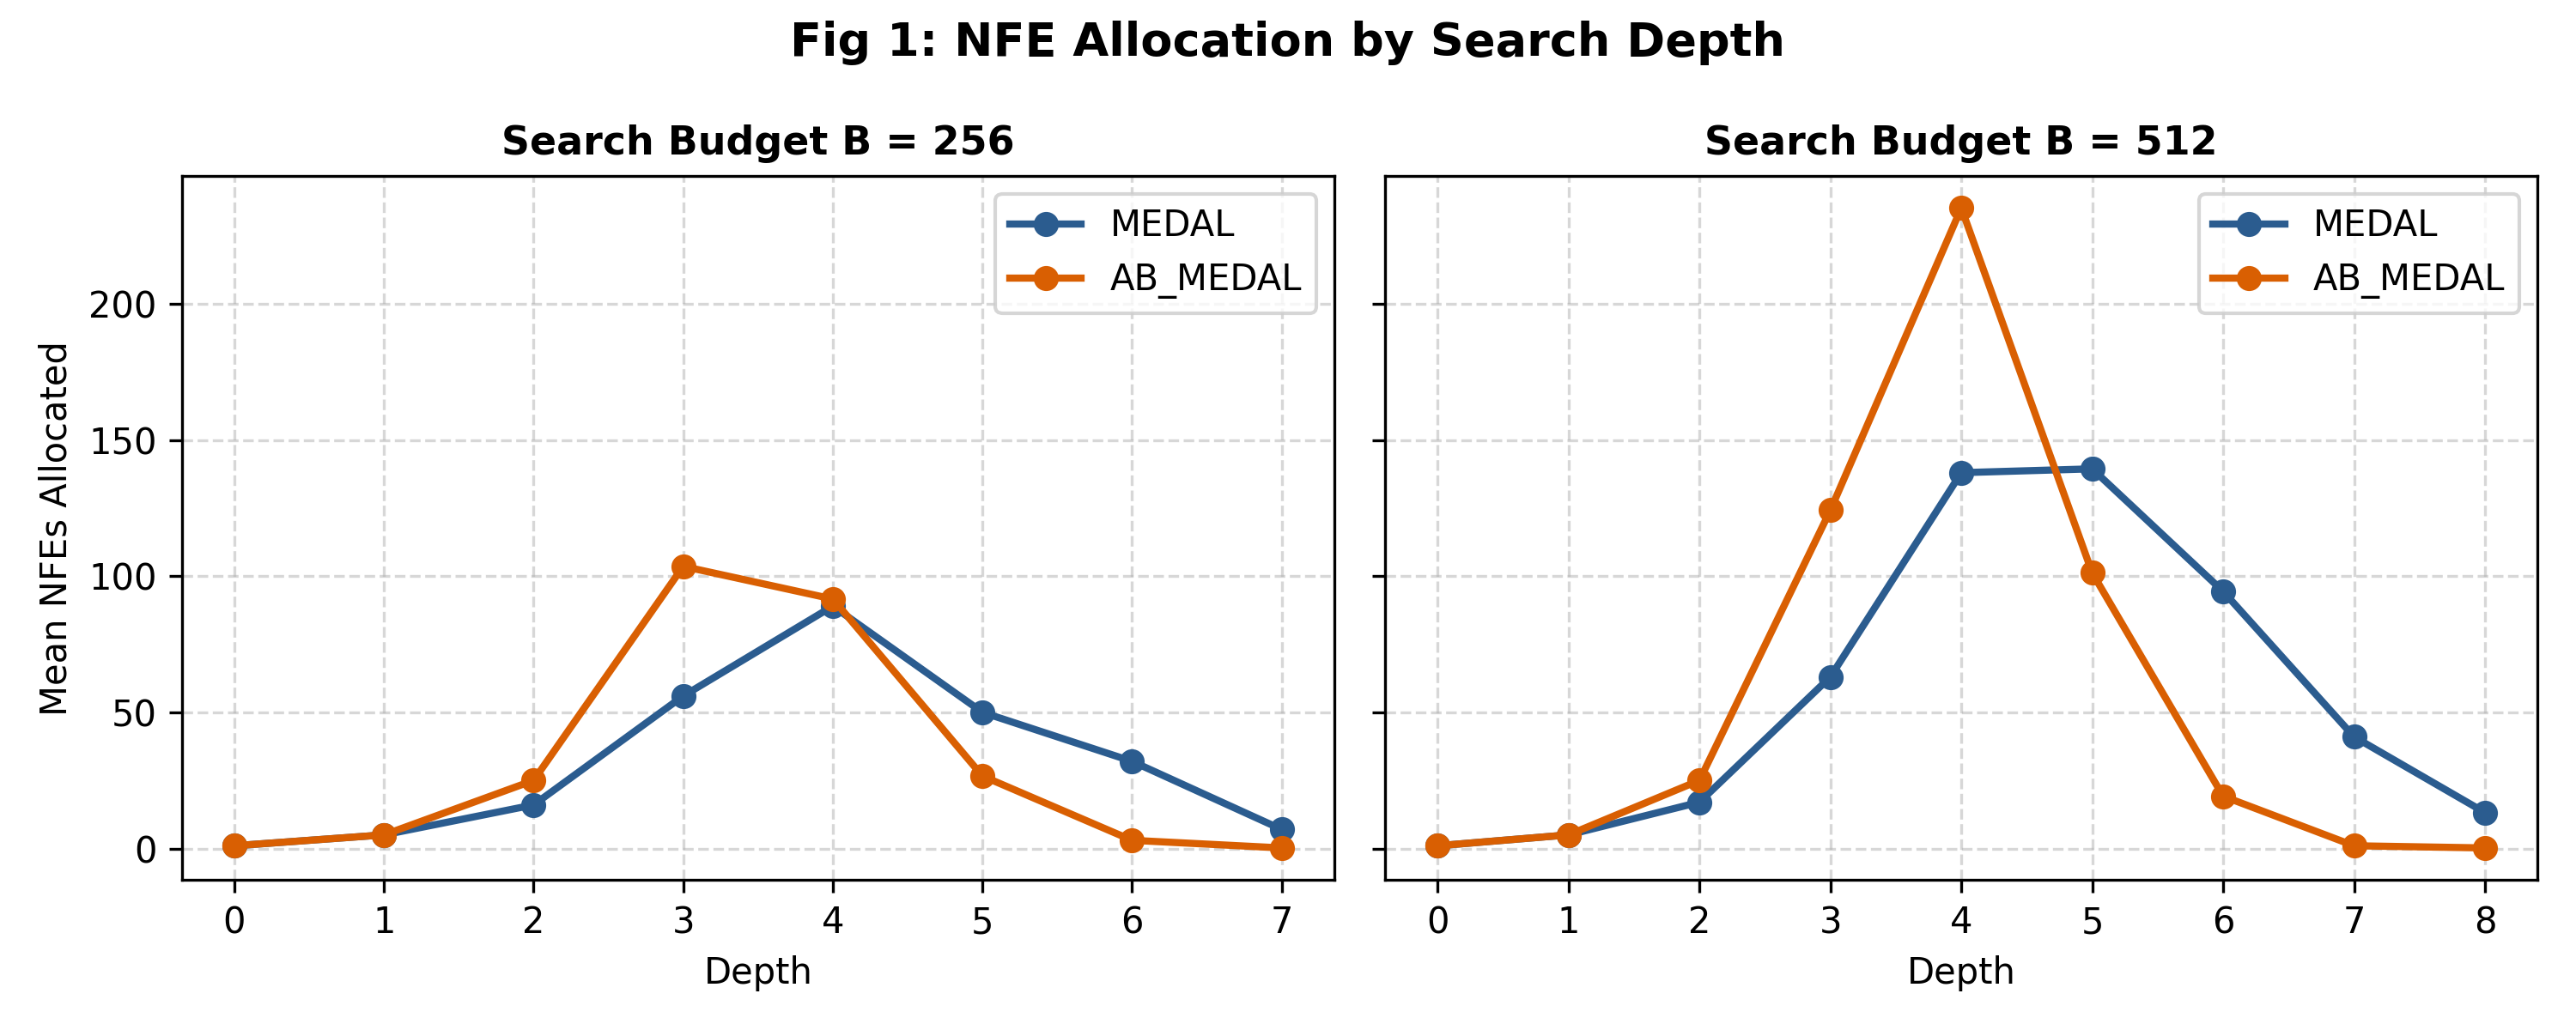

### Figure 2: Branching Factor Distribution — Children per expanded parent

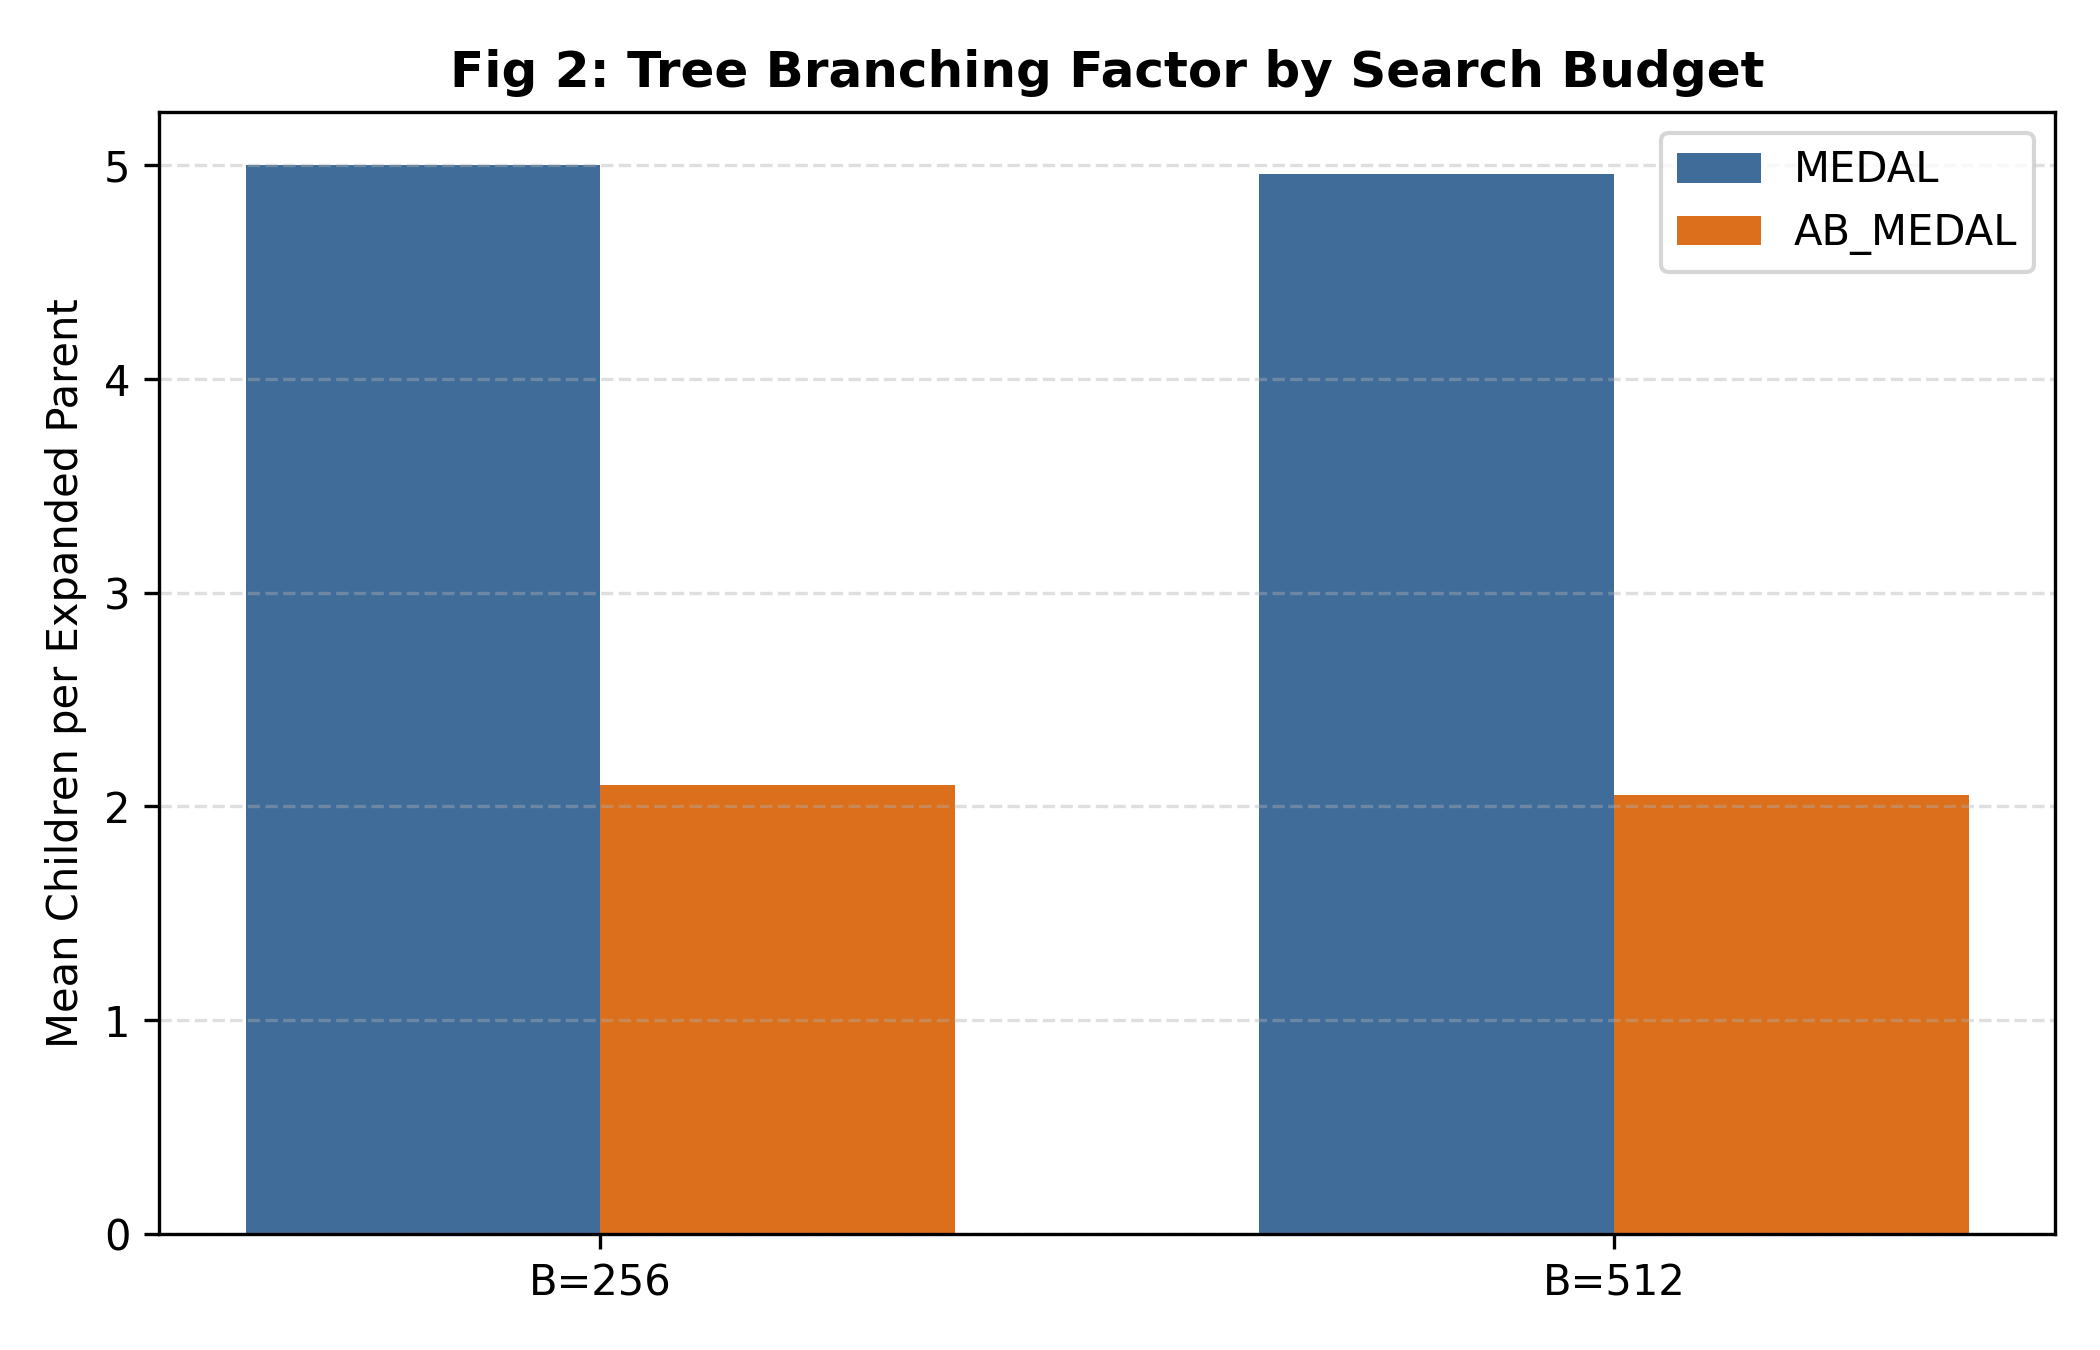

### Figure 3: Candidate Density vs Depth — Minimum-C availability and selection depth

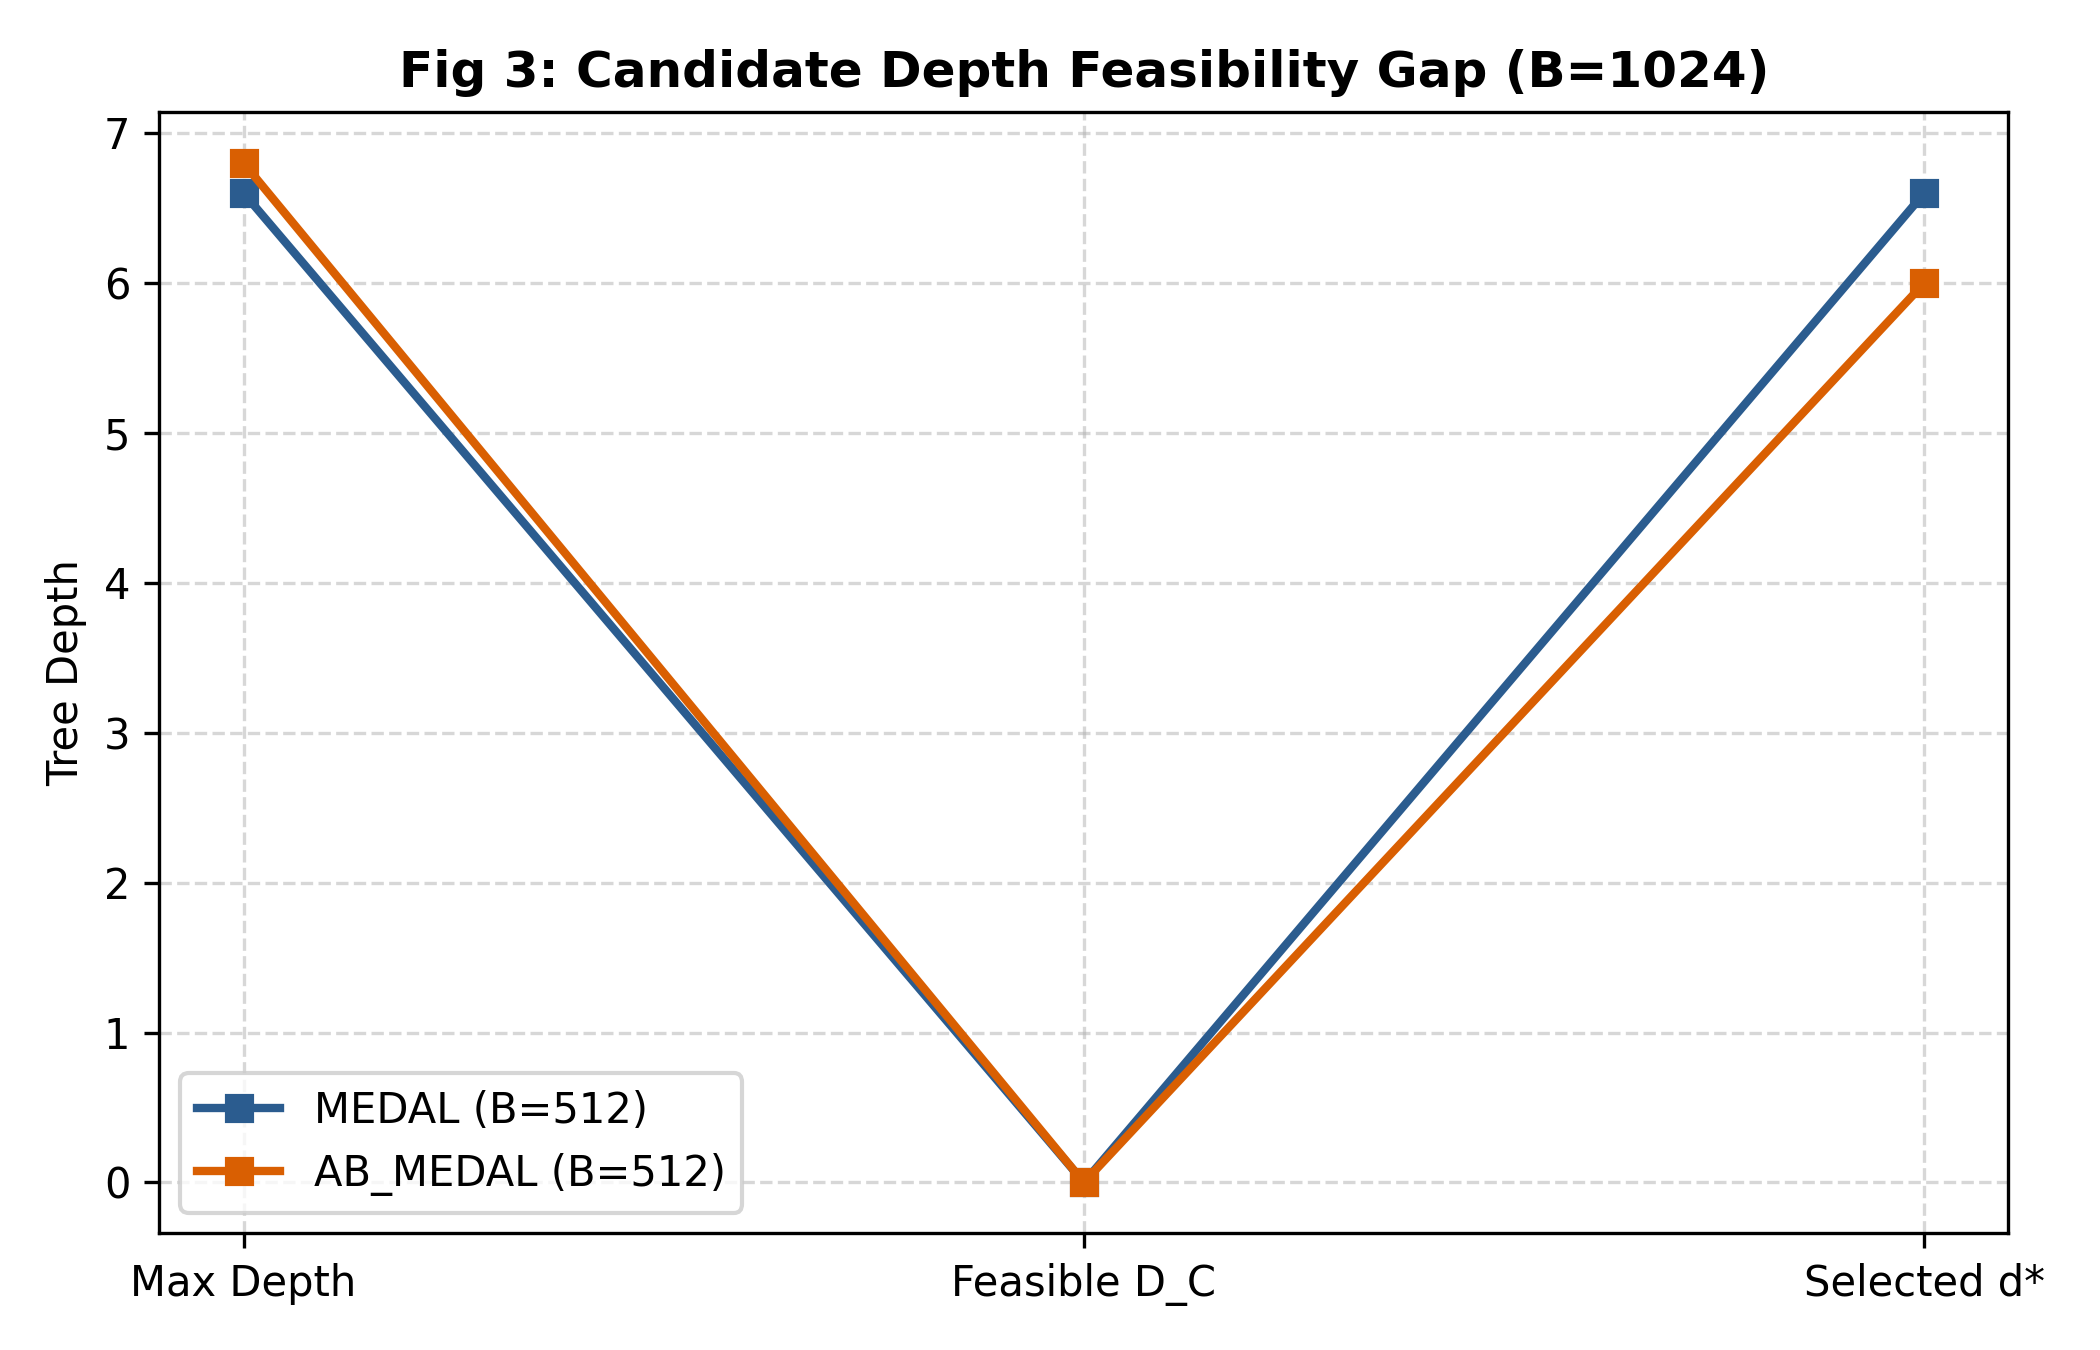

### Figure 4: Root-Subtree Compute Concentration — Search effort across root branches

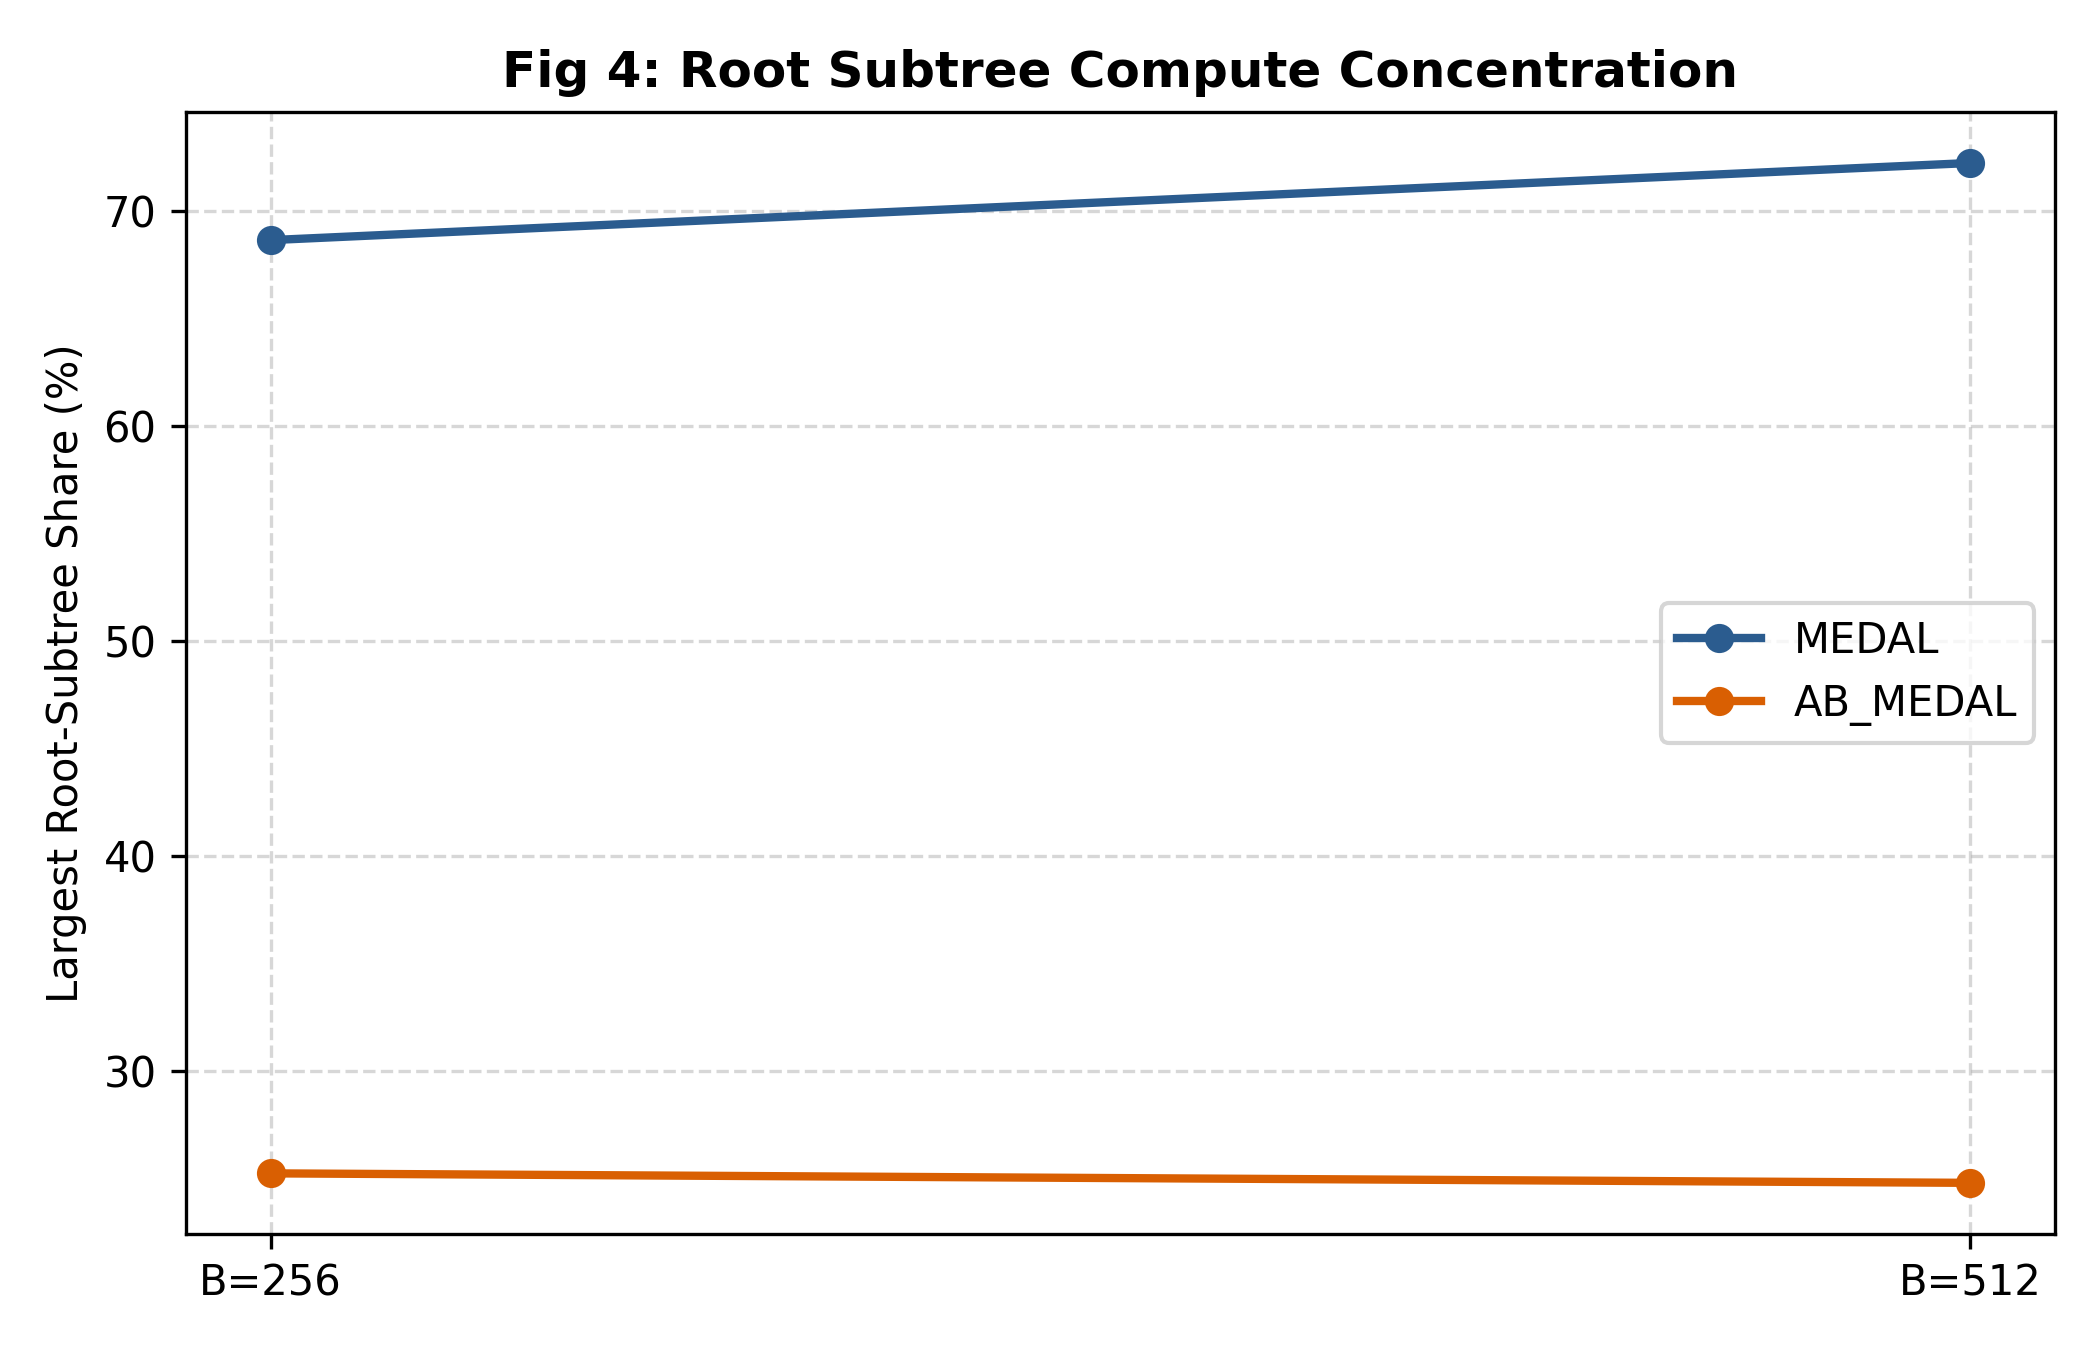

### Figure 5: Reward and Search Redundancy — Negative IG rates and duplicate states

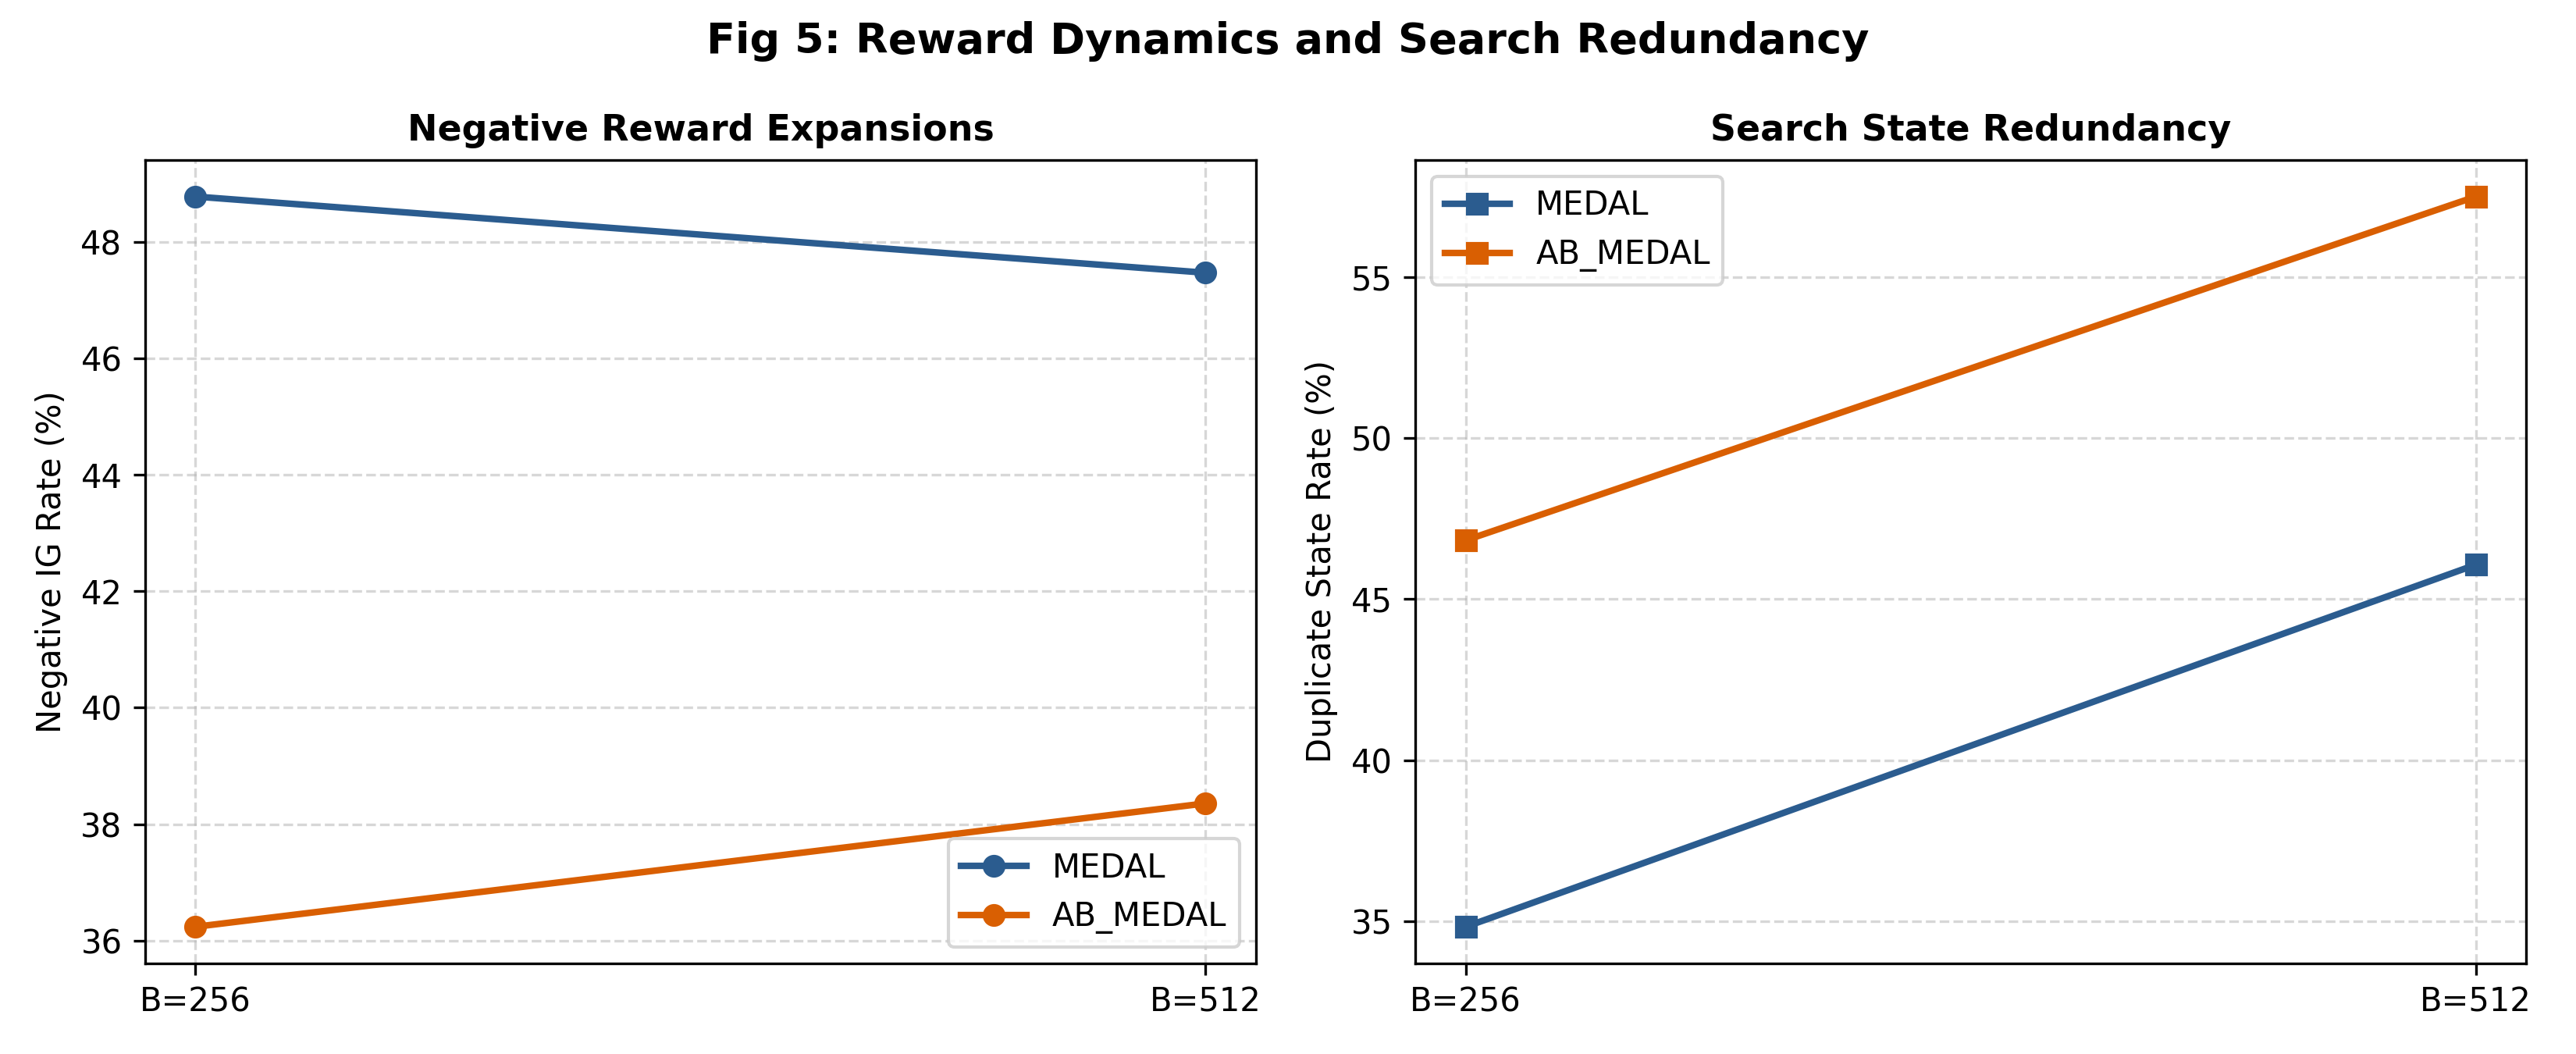

### Figure 6: Accuracy vs Search Budget — Performance scaling curve

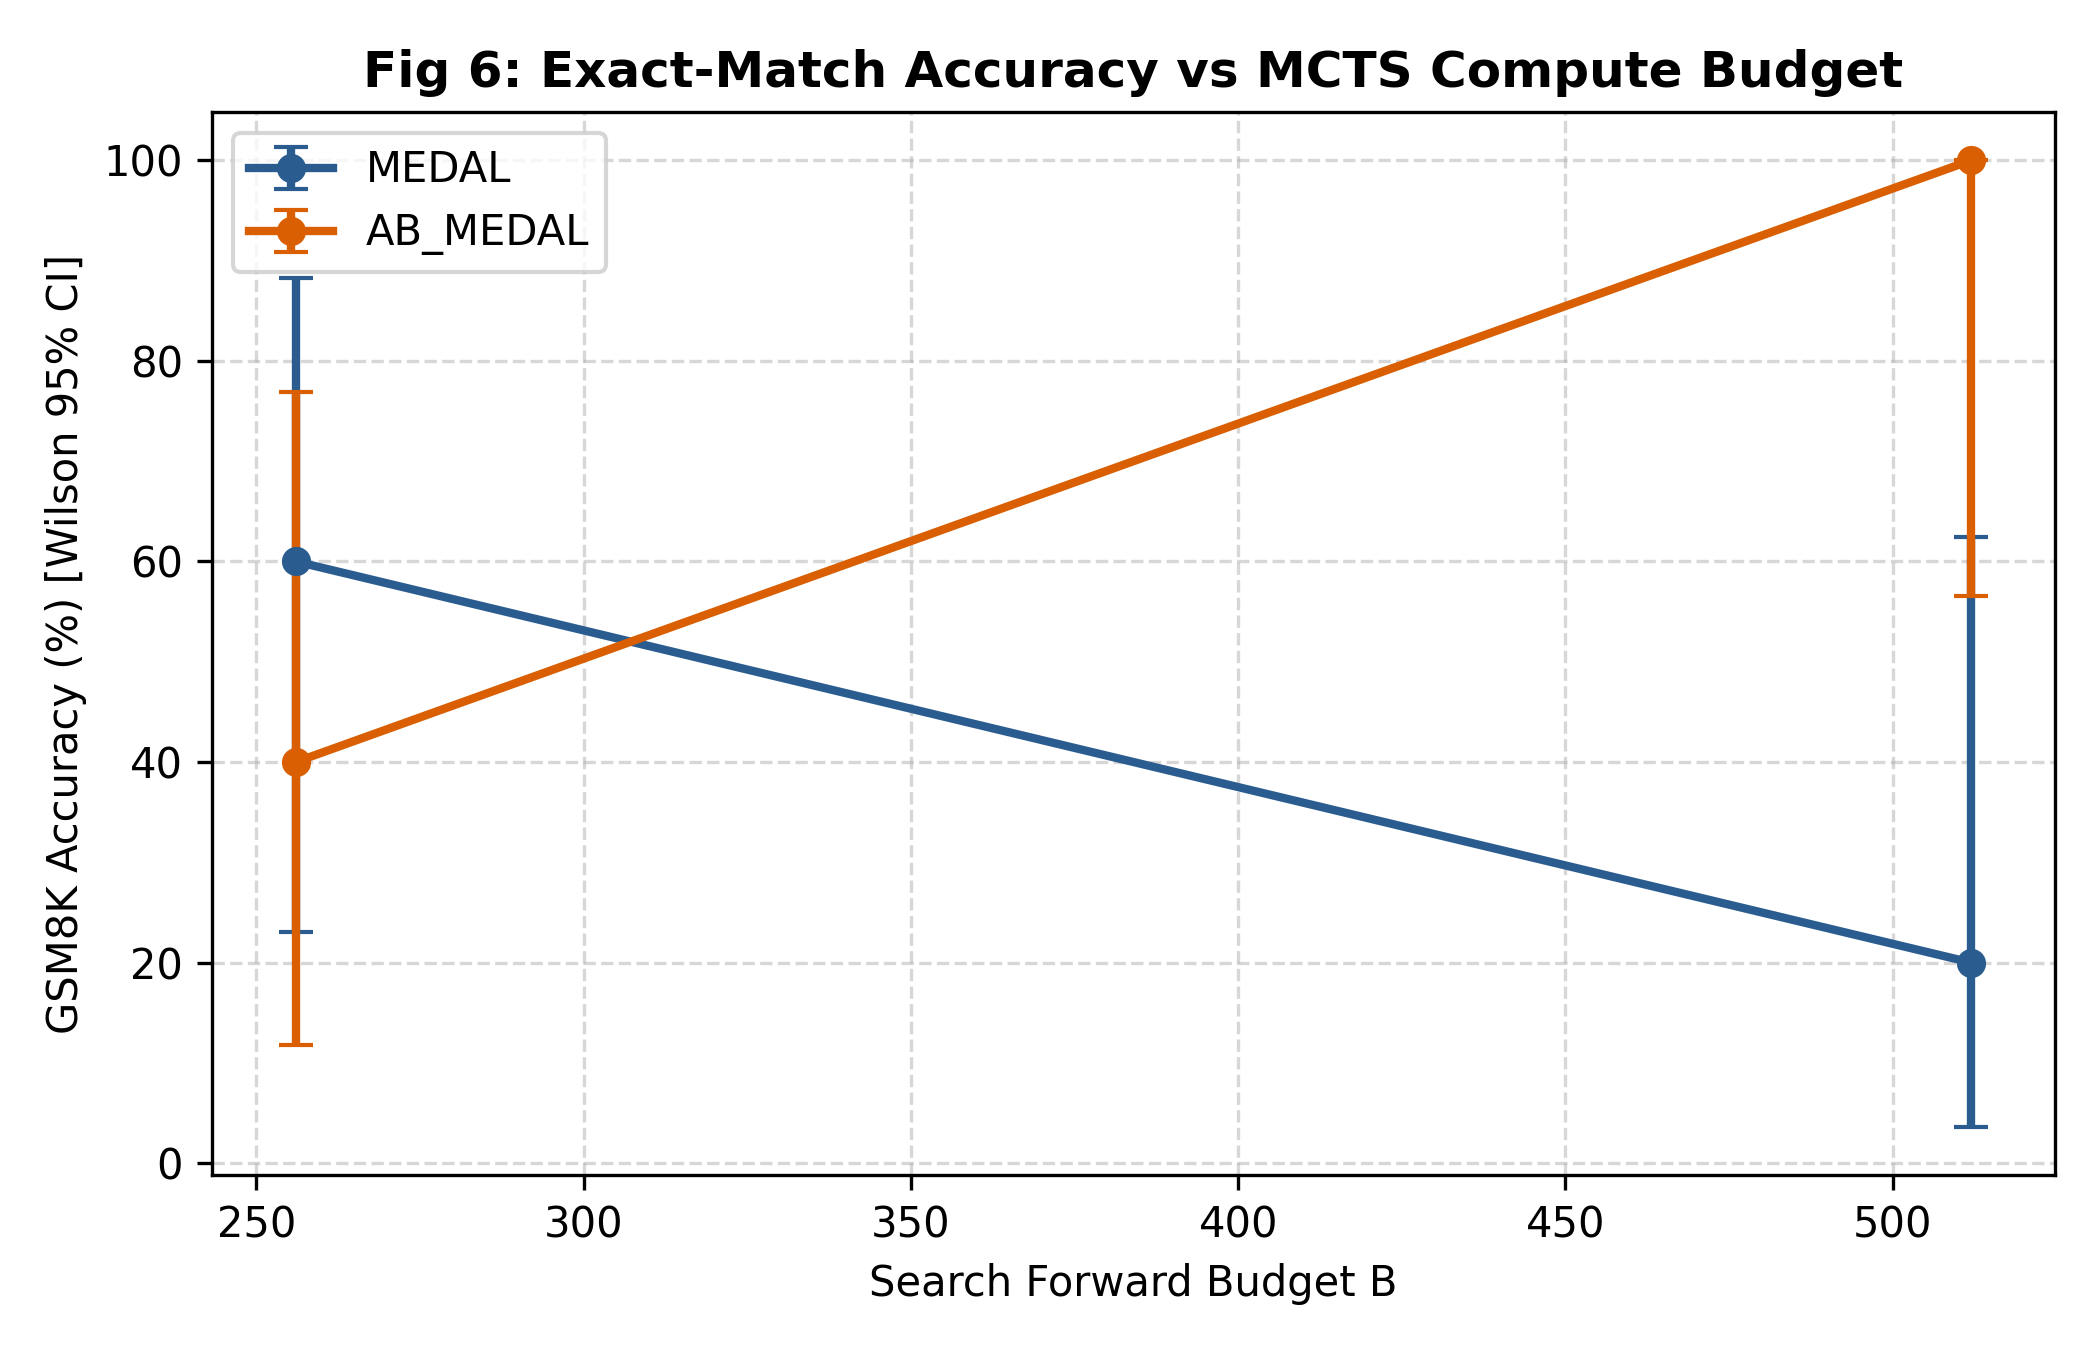

In [13]:
from dlm_project.tasks.gsm8k.e3_analysis import analyze_e3_stage
from IPython.display import Image, display, Markdown

print("Running E3 Offline Tree Allocation & Topology Analysis...")
e3_q, e3_agg = analyze_e3_stage(
    results_dir=OUTPUT_DIR / STAGE,
    output_dir=OUTPUT_DIR / "summaries",
    stage=STAGE,
    methods=tuple(METHODS),
    budgets=tuple(BUDGETS),
)
print("✓ E3 Analysis Completed successfully.")

figures_dir = OUTPUT_DIR / "summaries" / "e3_figures"
fig_titles = {
    "fig1_nfe_by_depth": "Figure 1: NFE Allocation by Tree Depth — MEDAL vs AB-MEDAL across budgets",
    "fig2_branching_factors": "Figure 2: Branching Factor Distribution — Children per expanded parent",
    "fig3_candidate_density": "Figure 3: Candidate Density vs Depth — Minimum-C availability and selection depth",
    "fig4_root_subtrees": "Figure 4: Root-Subtree Compute Concentration — Search effort across root branches",
    "fig5_reward_redundancy": "Figure 5: Reward and Search Redundancy — Negative IG rates and duplicate states",
    "fig6_accuracy_vs_budget": "Figure 6: Accuracy vs Search Budget — Performance scaling curve",
}

for fig_key, title in fig_titles.items():
    png_path = figures_dir / f"{fig_key}.png"
    if png_path.is_file():
        display(Markdown(f"### {title}"))
        display(Image(filename=str(png_path)))


## 12. Interactive Search Tree & Decision Trace Inspector
Examine candidate shortlists, selection gap $\Delta_d = d_{\max} - d^*$, and Student-t GEN/CONT posterior traces for any question.

In [15]:
# # import json

# # INSPECT_QUESTION_IDX = 0
# # INSPECT_BUDGET = 256

# # q_info = ctx["examples"][INSPECT_QUESTION_IDX]
# # ex_id = q_info["example_id"]
# # print(f"=== Inspecting Question {ex_id} (Budget {INSPECT_BUDGET}) ===")
# # print("Question:\n", q_info["question"])
# # print("Reference Answer:", q_info.get("reference_solution", "").split("####")[-1].strip())


# for m in METHODS:
#     sel_path = OUTPUT_DIR / STAGE / m / ex_id / "checkpoints" / str(INSPECT_BUDGET) / "selection.json"
#     if sel_path.is_file():
#         sel_record = json.loads(sel_path.read_text())
#         print(f"\n--- {m.upper()} Selection Record ---")
#         print(f"  Selected Node: {sel_record['selected_node_id']} | Depth: {sel_record['selected_depth']}")
#         print(f"  Selected Q: {sel_record['selected_q']:.4f}")
#         print(f"  Max Depth Reached: {sel_record['max_depth_reached']} | Selection Gap (Δd): {sel_record['selection_depth_gap']}")
#         print(f"  Distinct Candidates by Depth: {sel_record['distinct_candidates_by_depth']}")
#         print(f"  Shortlist Node IDs: {sel_record['shortlist_ids']}")

# # For AB-MEDAL, inspect decision events
# dec_path = OUTPUT_DIR / STAGE / "ab_medal" / ex_id / "decisions.jsonl"
# if dec_path.is_file():
#     dec_events = [json.loads(line) for line in dec_path.read_text().splitlines()]
#     print(f"\n--- AB-MEDAL Decision Trace Sample (first 10 of {len(dec_events)} decisions) ---")
#     for d in dec_events[:10]:
#         print(f"  Cycle {d.get('cycle')}: parent node {d.get('node_id')} -> {d.get('decision')} (forced={d.get('forced')})")

=== Inspecting Question train:2337 (Budget 256) ===
Question:
 The P.T.O. decided to provide shirts for the elementary students for track and field day. Each grade was given a different color. 101 Kindergartners wore orange shirts that cost $5.80 each. 113 first graders wore yellow shirts that cost $5 each. 107 second graders wore blue shirts that cost $5.60 each. 108 third graders wore green shirts that cost $5.25 each. How much did the P.T.O. spend on shirts for field day?
Reference Answer: 2,317


In [36]:
import json
from pathlib import Path
import os

INSPECT_QUESTION_IDX = 3
INSPECT_BUDGET = 512

# 1. Ensure Google Drive is mounted if running in Colab
if Path("/content").is_dir() and not Path("/content/drive/MyDrive").is_dir():
    print("[Notice] Mounting Google Drive to access saved results...")
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print(f"  Could not auto-mount Google Drive: {e}")

# 2. Resolve the actual results root directory
search_roots = [
    Path("/content/drive/MyDrive/CSCI544-DLM/results/e1_e3"),
    globals().get("OUTPUT_DIR"),
    Path("/content/CSCI544-DLM/.cache/e1_e3/results/e1_e3"),
    globals().get("REPO_DIR", Path.cwd()) / ".cache/e1_e3/results/e1_e3",
    Path.cwd() / "results/e1_e3",
]
actual_output_dir = next(
    (p for p in search_roots if p is not None and (p / STAGE).is_dir()),
    globals().get("OUTPUT_DIR", Path("results/e1_e3"))
)

q_info = ctx["examples"][INSPECT_QUESTION_IDX]
ex_id = q_info["example_id"]
print(f"=== Inspecting Question {ex_id} (Budget {INSPECT_BUDGET}) ===")
print("Question:\n", q_info["question"])
print("Reference Answer:", q_info.get("reference_solution", "").split("####")[-1].strip())
print(f"Results Directory: {actual_output_dir / STAGE} (exists: {(actual_output_dir / STAGE).exists()})")

for m in METHODS:
    chk_dir = actual_output_dir / STAGE / m / ex_id / "checkpoints" / str(INSPECT_BUDGET)
    sel_path = chk_dir / "selection.json"
    met_path = chk_dir / "metrics.json"
    tree_path = chk_dir / "tree.json"

    if sel_path.is_file() or met_path.is_file():
        sel_record = json.loads(sel_path.read_text()) if sel_path.is_file() else {}
        met_record = json.loads(met_path.read_text()) if met_path.is_file() else {}

        selected_id = sel_record.get("selected_node_id", met_record.get("selected_node_id"))
        selected_depth = sel_record.get("selected_depth", met_record.get("selected_depth"))

        selected_q = met_record.get("selected_q", sel_record.get("selected_q"))
        if selected_q is None and "node_statistics" in sel_record:
            selected_q = next((s["q_value"] for s in sel_record["node_statistics"] if s["node_id"] == selected_id), None)

        max_depth = met_record.get("max_depth_reached", sel_record.get("max_depth_reached", "N/A"))
        gap = met_record.get("selection_depth_gap", sel_record.get("selection_depth_gap", "N/A"))

        distinct_by_depth = met_record.get("distinct_candidates_by_depth") or sel_record.get("distinct_candidates_by_depth")
        if not distinct_by_depth and tree_path.is_file():
            tree_data = json.loads(tree_path.read_text())
            counts = {}
            for n in tree_data.get("nodes", []):
                counts.setdefault(n["depth"], set()).add(n.get("state_hash", n["node_id"]))
            distinct_by_depth = {d: len(s) for d, s in sorted(counts.items())}

        shortlist_ids = sel_record.get("shortlist_ids") or met_record.get("shortlist_node_ids", [])

        print(f"\n--- {m.upper()} Selection Record ---")
        print(f"  Selected Node: {selected_id} | Depth: {selected_depth}")
        print(f"  Selected Q: {selected_q:.4f}" if selected_q is not None else "  Selected Q: N/A")
        print(f"  Max Depth Reached: {max_depth} | Selection Gap (Δd): {gap}")
        print(f"  Distinct Candidates by Depth: {distinct_by_depth}")
        print(f"  Shortlist Node IDs: {shortlist_ids}")
    else:
        print(f"\n--- {m.upper()} Selection Record ---")
        print(f"  [Not Found] Expected path: {sel_path}")
        parent = chk_dir.parent
        if not parent.exists():
            print(f"  Parent directory does not exist: {parent}")
        elif parent.is_dir():
            print(f"  Available checkpoints for {ex_id}: {[p.name for p in parent.iterdir()]}")

# For AB-MEDAL, inspect decision events
dec_path = actual_output_dir / STAGE / "ab_medal" / ex_id / "decisions.jsonl"
if dec_path.is_file():
    dec_events = [json.loads(line) for line in dec_path.read_text().splitlines()]
    print(f"\n--- AB-MEDAL Decision Trace Sample (first 10 of {len(dec_events)} decisions) ---")
    for d in dec_events[:10]:
        print(f"  Cycle {d.get('cycle')}: parent node {d.get('node_id')} -> {d.get('decision')} (forced={d.get('forced')})")
else:
    print(f"\n--- AB-MEDAL Decision Trace Sample ---")
    print(f"  [Not Found] Decision trace not found at: {dec_path}")


=== Inspecting Question train:6499 (Budget 512) ===
Question:
 Tricia is a third of Amilia’s age and Amilia is a quarter of Yorick’s age. Yorick is twice Eugene’s age and Khloe is a third of Eugene’s age. Rupert is 10 years older than Khloe but 2 years younger than Vincent who is 22 years old. How old, in years, is Tricia?
Reference Answer: 5
Results Directory: /content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_1/results/e1_e3/dev (exists: True)

--- MEDAL Selection Record ---
  Selected Node: 492 | Depth: 6
  Selected Q: 0.0222
  Max Depth Reached: 6 | Selection Gap (Δd): 0
  Distinct Candidates by Depth: {0: 1, 1: 5, 2: 19, 3: 62, 4: 102, 5: 67, 6: 26}
  Shortlist Node IDs: [492, 495, 390]

--- AB_MEDAL Selection Record ---
  Selected Node: 198 | Depth: 6
  Selected Q: 0.0168
  Max Depth Reached: 8 | Selection Gap (Δd): 2
  Distinct Candidates by Depth: {0: 1, 1: 5, 2: 19, 3: 68, 4: 84, 5: 34, 6: 7, 7: 2, 8: 1}
  Shortlist Node IDs: [198, 254, 374]

--- AB-MEDAL Decision Trace

ls: cannot access '/content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_1': No such file or directory
ls: cannot access '/content/drive/MyDrive/CSCI544-DLM/results/e1_e3': No such file or directory
/content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_1 /results/e1_e3/dev/medal/train:2337
/content/drive/MyDrive/CSCI544-DLM/LLaDA/GSM8K/experiment_1 /results/e1_e3/dev/ab_medal/train:2337


## 13. AB-MCTS-Style Tree Comparisons
Compare **MEDAL and AB-MEDAL for the question and budget selected in Section 12**, using only saved checkpoints. No GPU, model, tokenizer, or additional inference is needed for this section.

Following [AB-MCTS Figure 7](https://arxiv.org/html/2503.04412v5#S4.F7), every evaluated node is numbered by **evaluation order** (which can differ from its node ID). Here nodes are **partial token states**, rather than the complete solutions shown in the paper. Duplicate states stay separate to show the actual search effort.

Two figures use the **same full-tree layout**:
- **Immediate IG:** color is the signed information-gain reward from evaluating that node; the root has no IG and is neutral gray.
- **Mean Q-value:** color is the backed-up mean reward, including the root's Q-value.

Each figure uses a shared, zero-centered color scale across both methods. Gold outlines mark the shortlist, a heavy black outline marks the selected node, and black edges trace its path. Colors are search rewards, **not answer correctness**; final completion correctness is reported separately in each panel.

The default inputs reuse the current inspector settings and resolved results directory. Set the three overrides below to plot saved artifacts in a fresh CPU session without running earlier GPU cells. The results directory must contain `medal/` and `ab_medal/`; no other question or budget is substituted if files are missing. PNGs are bounded previews; **zoom the vector PDF to read every number on a dense 256/512-node tree**.


In [ ]:
from pathlib import Path

# Leave these as None to reuse Section 12, or set all three for standalone plotting.
TREE_RESULTS_DIR_OVERRIDE = None  # e.g. Path("/content/drive/MyDrive/CSCI544-DLM/results/e1_e3/dev")
TREE_EXAMPLE_ID_OVERRIDE = None   # e.g. "train:6499"
TREE_BUDGET_OVERRIDE = None       # e.g. 512

if TREE_RESULTS_DIR_OVERRIDE is not None:
    tree_results_dir = Path(TREE_RESULTS_DIR_OVERRIDE).expanduser().resolve()
elif "actual_output_dir" in globals() and "STAGE" in globals():
    tree_results_dir = (Path(actual_output_dir) / STAGE).expanduser().resolve()
else:
    raise RuntimeError("Run the Section 12 inspector, or set TREE_RESULTS_DIR_OVERRIDE to the saved stage directory.")

if TREE_EXAMPLE_ID_OVERRIDE is not None:
    tree_example_id = TREE_EXAMPLE_ID_OVERRIDE
elif "ctx" in globals() and "INSPECT_QUESTION_IDX" in globals():
    tree_example_id = ctx["examples"][INSPECT_QUESTION_IDX]["example_id"]
else:
    raise RuntimeError("Run the Section 12 inspector, or set TREE_EXAMPLE_ID_OVERRIDE to the saved question ID.")

tree_budget = TREE_BUDGET_OVERRIDE if TREE_BUDGET_OVERRIDE is not None else globals().get("INSPECT_BUDGET")
if tree_budget is None:
    raise RuntimeError("Run the Section 12 inspector, or set TREE_BUDGET_OVERRIDE to a saved checkpoint budget.")

tree_output_dir = (
    tree_results_dir.parent / "summaries" / "e3_figures" / "trees"
    / tree_results_dir.name / tree_example_id
)
print(f"Selected question: {tree_example_id} | Budget: {tree_budget}")
print(f"Results directory: {tree_results_dir}")
for tree_method in ("medal", "ab_medal"):
    tree_checkpoint_dir = tree_results_dir / tree_method / tree_example_id / "checkpoints" / str(tree_budget)
    for tree_filename in ("tree.json", "selection.json", "metrics.json"):
        print(f"  {tree_method}: {tree_checkpoint_dir / tree_filename}")
print(f"Figure export directory: {tree_output_dir}")


In [ ]:
from dlm_project.tasks.gsm8k.e3_tree_plots import plot_e3_tree_comparison
from IPython.display import Image, Markdown, display

tree_exports = {}
for tree_color_by, tree_title in (
    ("immediate_reward", "Immediate information gain (IG)"),
    ("mean_reward", "Backed-up mean Q-value"),
):
    tree_paths = plot_e3_tree_comparison(
        results_dir=tree_results_dir,
        output_dir=tree_output_dir,
        example_id=tree_example_id,
        budget=tree_budget,
        color_by=tree_color_by,
    )
    tree_exports[tree_color_by] = tree_paths
    display(Markdown(f"### {tree_title}: MEDAL vs AB-MEDAL"))
    display(Image(filename=str(tree_paths["png"]), width=1400))
    print(f"PNG preview: {tree_paths['png']}")
    print(f"Vector PDF (zoom for all node labels): {tree_paths['pdf']}")


## 14. Synchronize All Artifacts to Google Drive
Explicitly flush and sync all in-memory filesystem buffers to Google Drive cloud storage so all traces, trees, completions, CSVs, and plots are safely persisted and reconstructible even if Colab disconnects.

In [ ]:
if IN_COLAB:
    from google.colab import drive
    drive.flush_and_unmount()
    drive.mount("/content/drive")
    print("✓ Google Drive synchronization complete. All artifacts safely flushed to Drive.")
else:
    print(f"✓ Local artifacts safely saved at: {OUTPUT_DIR}")